In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

# Clasificación de Imágenes mediante Machine Learning Inspirado en la Cuántica

En este cuaderno abordamos la clasificación de imágenes complejas (Dataset FashionMNIST) utilizando metodologías de **Machine Learning Inspirado en la Cuántica (Quantum-Inspired Machine Learning)**.

No se utiliza computación cuántica real (basada en hardware de qubits físicos), sino que ejecutamos simulaciones en hardware clásico empleando el **formalismo matemático de la mecánica cuántica de muchos cuerpos**. Específicamente, hacemos uso de las **Redes de Tensores**, herramientas diseñadas originalmente para simular el entrelazamiento cuántico en materiales, adaptándolas aquí para comprimir y extraer características de datos visuales clásicos.

### 1. Carga del Dataset (FashionMNIST)
Comenzamos importando las librerías base de `PyTorch` y descargando el conjunto de datos. FashionMNIST presenta un reto visual superior al MNIST tradicional de dígitos, lo que nos permitirá evaluar la capacidad real del modelo para trazar fronteras de decisión complejas.

In [ ]:
import torch
from torchvision.datasets import FashionMNIST
from torchvision import transforms

train_dataset = FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.91MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 279kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.98MB/s]


El algoritmo implementa un modelo de clasificación basado en Redes de Tensores empleando un mapeo de características local (Feature-mapped MPS). A diferencia de la representación Quantics Tensor Train (QTT) —que codifica las dimensiones de la imagen en escalas logarítmicas utilizando los bits de los índices—, este enfoque utiliza un mapeo espacial directo (Stoudenmire & Schwab, 2016).

### 2. Preprocesamiento y Mapeo a la Representación *Quantics*

En Deep Learning tradicional, las redes neuronales procesan los píxeles directamente como una matriz espacial bidimensional. Sin embargo, para explotar las ventajas de la compresión cuántica, utilizamos la representación **Quantics Tensor Train (QTT)**.

Para ello, primero reducimos las imágenes a una resolución de **$8 \times 8$ píxeles**. Esto nos genera un vector unidimensional de $N=64$ características.
El poder de la representación *Quantics* radica en la **indexación binaria**: dado que $64 = 2^6$, el modelo no necesita 64 tensores (uno por píxel), sino **únicamente 6 tensores** (uno por cada bit de la coordenada espacial). Este preprocesamiento prepara el tensor plano para que la red extraiga las correlaciones espaciales desde la escala más macroscópica hasta los detalles más finos.


Cada píxel individual $x_i$ (normalizado en el rango $[0,1]$) se mapea a un espacio local de dimensión 2 (equivalente a un qubit virtual) utilizando una transformación no lineal trigonométrica:$$\phi(x_i) = \begin{bmatrix} \cos\left(\frac{\pi}{2}x_i\right) \\ \sin\left(\frac{\pi}{2}x_i\right) \end{bmatrix}$$Esta función garantiza que las representaciones de los píxeles posean norma unitaria, permitiendo que la red asimile correlaciones complejas y no lineales entre diferentes regiones de la imagen

En la física cuántica original, una red MPS se optimiza utilizando el algoritmo **DMRG (Density Matrix Renormalization Group)**, el cual realiza "barridos" (*sweeps*) optimizando un núcleo a la vez de forma secuencial mientras congela los demás.

En nuestro pipeline híbrido implementado en PyTorch, realizamos una **optimización variacional basada en gradientes (Backpropagation)**. En cada paso del entrenamiento:
1. El algoritmo inyecta los datos de la imagen en la cadena MPS.
2. Contrae secuencialmente los núcleos mediante operaciones de producto tensorial aceleradas (`torch.einsum`).
3. Calcula la pérdida de entropía cruzada (*Cross-Entropy Loss*) en la salida.
4. El optimizador `Adam` calcula los gradientes y **actualiza todos los núcleos simultáneamente** en lugar de uno a uno. Esto une la robustez de representación de la física cuántica con la velocidad de cómputo y paralelización en GPU del Deep Learning clásico.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np


sample_train = 5000
sample_test = 1000

X_train_raw = train_dataset.data[:sample_train].float() / 255.
y_train = train_dataset.targets[:sample_train]
X_test_raw = test_dataset.data[:sample_test].float() / 255.
y_test = test_dataset.targets[:sample_test]

# Escalamos a 8x8
X_train_small = F.interpolate(X_train_raw.unsqueeze(1), size=(8, 8), mode='bilinear', align_corners=False).squeeze(1)
X_test_small = F.interpolate(X_test_raw.unsqueeze(1), size=(8, 8), mode='bilinear', align_corners=False).squeeze(1)

X_train_flat = X_train_small.flatten(start_dim=1) # (5000, 64)
X_test_flat = X_test_small.flatten(start_dim=1)   # (1000, 64)

def image_to_mps_features(images_flat):
    phi_0 = torch.cos(np.pi / 2 * images_flat)
    phi_1 = torch.sin(np.pi / 2 * images_flat)
    return torch.stack([phi_0, phi_1], dim=-1)

X_train_q = image_to_mps_features(X_train_flat)
X_test_q  = image_to_mps_features(X_test_flat)

print("Formato de alta capacidad:", X_train_q.shape)  # torch.Size([5000, 64, 2])



class QTTClassifier(nn.Module):
    def __init__(self, bond_dim, num_sites, num_classes=10):
        super().__init__()
        self.num_sites = num_sites
        self.cores = nn.ParameterList()

        # Todos los cores intermedios mantienen una estructura homogénea
        for k in range(num_sites):
            Dl = 1 if k == 0 else bond_dim
            Dr = bond_dim  # Mantenemos bond_dim constante al final de la cadena

            core = nn.Parameter(torch.randn(Dl, 2, Dr) * 0.1)
            self.cores.append(core)

        # Capa lineal clásica: Recibe el vector del MPS y extrae las clases óptimas
        self.classifier = nn.Linear(bond_dim, num_classes)

    def forward(self, x):
        batch = x.shape[0]

        # Contracción del Sitio 0
        v = torch.einsum('dph,bp->bdh', self.cores[0], x[:, 0]).squeeze(1)
        v = v / (torch.norm(v, dim=1, keepdim=True) + 1e-8)

        # Contracción del resto de los sitios (incluyendo el último)
        for k in range(1, self.num_sites):
            v = torch.einsum('bd,dph,bp->bh', v, self.cores[k], x[:, k])
            v = v / (torch.norm(v, dim=1, keepdim=True) + 1e-8)

        # v ahora es un vector denso de tamaño (batch, bond_dim)
        # Pasamos por el clasificador lineal final
        logits = self.classifier(v)
        return logits


# Usamos 64 sitios (8x8) y un bond_dim de 64 para albergar relaciones complejas
model = QTTClassifier(bond_dim=64, num_sites=64, num_classes=10)

dataset = TensorDataset(X_train_q, y_train)
loader  = DataLoader(dataset, batch_size=64, shuffle=True)

# Bajamos ligeramente el LR a 1e-3 para estabilizar la cadena más larga de 64 bloques
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.CrossEntropyLoss()

for epoch in range(60):
    total_loss = 0
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(loader)

    if epoch % 5 == 0 or epoch == 39:
        model.eval()
        with torch.no_grad():
            preds = model(X_test_q).argmax(dim=1)
            acc = (preds == y_test).float().mean()
        print(f"Epoch {epoch:2d} | Loss={avg_loss:.4f} | Test acc={acc:.4f}")
    else:
        print(f"Epoch {epoch:2d} | Loss={avg_loss:.4f}")

Formato de alta capacidad: torch.Size([5000, 64, 2])
Epoch  0 | Loss=2.0093 | Test acc=0.5610
Epoch  1 | Loss=1.7471
Epoch  2 | Loss=1.6406
Epoch  3 | Loss=1.4098
Epoch  4 | Loss=1.2896
Epoch  5 | Loss=1.1946 | Test acc=0.6110
Epoch  6 | Loss=1.1097
Epoch  7 | Loss=1.0417
Epoch  8 | Loss=0.9680
Epoch  9 | Loss=0.9304
Epoch 10 | Loss=0.8976 | Test acc=0.6820
Epoch 11 | Loss=0.8729
Epoch 12 | Loss=0.8409
Epoch 13 | Loss=0.8152
Epoch 14 | Loss=0.7809
Epoch 15 | Loss=0.7787 | Test acc=0.6910
Epoch 16 | Loss=0.7596
Epoch 17 | Loss=0.7485
Epoch 18 | Loss=0.7274
Epoch 19 | Loss=0.7149
Epoch 20 | Loss=0.7022 | Test acc=0.7230
Epoch 21 | Loss=0.6722
Epoch 22 | Loss=0.6849
Epoch 23 | Loss=0.6791
Epoch 24 | Loss=0.6838
Epoch 25 | Loss=0.6669 | Test acc=0.7370
Epoch 26 | Loss=0.6447
Epoch 27 | Loss=0.6338
Epoch 28 | Loss=0.6184
Epoch 29 | Loss=0.6203
Epoch 30 | Loss=0.6057 | Test acc=0.7180
Epoch 31 | Loss=0.6010
Epoch 32 | Loss=0.5759
Epoch 33 | Loss=0.6037
Epoch 34 | Loss=0.5689
Epoch 35 | Loss=

In [ ]:
from sklearn.metrics import classification_report

model.eval()
with torch.no_grad():
    preds = model(X_test_q).argmax(dim=1)

print(classification_report(
    y_test.cpu(),
    preds.cpu(),
    digits=4
))

              precision    recall  f1-score   support

           0     0.7935    0.6822    0.7337       107
           1     0.8596    0.9333    0.8950       105
           2     0.5649    0.6667    0.6116       111
           3     0.6939    0.7312    0.7120        93
           4     0.6364    0.5478    0.5888       115
           5     0.9231    0.8276    0.8727        87
           6     0.4299    0.4742    0.4510        97
           7     0.8660    0.8842    0.8750        95
           8     0.9186    0.8316    0.8729        95
           9     0.8469    0.8737    0.8601        95

    accuracy                         0.7400      1000
   macro avg     0.7533    0.7453    0.7473      1000
weighted avg     0.7476    0.7400    0.7417      1000



### 3. Arquitectura del Modelo: Quantics Tensor Train Híbrido (TT-NN)

El modelo `TrueQTTClassifier` sustituye los pesos de una red densa clásica por una cadena factorizada de tensores (*Tensor Train*).

* **Dimensión de Enlace (`bond_dim`):** Es el hiperparámetro crítico que actúa como un cuello de botella informacional. Controla el análogo a la "Entropía de Entrelazamiento" del sistema, regularizando el aprendizaje y evitando de forma natural el sobreajuste (*overfitting*).
* **Ruptura del Techo Lineal (Hibridación TT-NN):** Un QTT puro que devuelve las clases directamente opera matemáticamente como un clasificador lineal (lo que limita su precisión teórica en torno al 74%). Para dotar al espacio latente de la capacidad de curvar las fronteras de decisión, hemos implementado una **Red Neuronal de Trenes de Tensores (TT-NN)**: el QTT extrae un vector altamente entrelazado que es proyectado a través de una función de activación no lineal (`ReLU`) y clasificado por una capa densa clásica.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

sample_train = 5000
sample_test = 1000

X_train_raw = train_dataset.data[:sample_train].float() / 255.
y_train = train_dataset.targets[:sample_train]
X_test_raw = test_dataset.data[:sample_test].float() / 255.
y_test = test_dataset.targets[:sample_test]

# Escalamos a 8x8 (total de 64 píxeles = 2^6)
X_train_small = F.interpolate(X_train_raw.unsqueeze(1), size=(8, 8), mode='bilinear', align_corners=False).squeeze(1)
X_test_small = F.interpolate(X_test_raw.unsqueeze(1), size=(8, 8), mode='bilinear', align_corners=False).squeeze(1)

# En QTT puro, NO usamos Feature Map trigonométrico.
# Se inyectan los píxeles aplanados directamente.
X_train_flat = X_train_small.flatten(start_dim=1) # (5000, 64)
X_test_flat = X_test_small.flatten(start_dim=1)   # (1000, 64)



#  MODELO QUANTICS TENSOR TRAIN (QTT)

class TrueQTTClassifier(nn.Module):
    def __init__(self, bond_dim, num_pixels=64, num_classes=10):
        super().__init__()

        self.num_sites = int(np.log2(num_pixels))
        self.cores = nn.ParameterList()

        for k in range(self.num_sites):
            Dl = 1 if k == 0 else bond_dim

            # CAMBIO 1: El último tensor ya NO baja a num_classes.
            # Ahora todos se mantienen en bond_dim para acumular información.
            Dr = bond_dim

            # Inicialización
            core = nn.Parameter(torch.randn(Dl, 2, Dr) / np.sqrt(Dl * 2))
            self.cores.append(core)

        # CAMBIO 2: Añadimos la capa lineal que recibe el vector del QTT
        self.classifier = nn.Linear(bond_dim, num_classes)

    def forward(self, x):
        batch = x.shape[0]
        v = x.view(batch, 1, 2, -1)

        # Contracción QTT
        for k in range(self.num_sites):
            core = self.cores[k]
            v = torch.einsum('l p r, b l p k -> b r k', core, v)

            if k < self.num_sites - 1:
                v = v.view(batch, core.shape[2], 2, -1)

        # Tras iterar, v tiene forma (batch, bond_dim, 1)
        # CAMBIO 3: Introducimos tu código exacto aquí
        v = v.squeeze(-1)            # Nos quedamos con (batch, bond_dim)

        v = F.relu(v)                # 1. Aplicamos no-linealidad clásica (rompemos el límite lineal)
        logits = self.classifier(v)  # 2. Capa de clasificación final

        return logits

# ENTRENAMIENTO DEL QTT

# bond_dim=16 es equivalente a un entrelazamiento muy alto en solo 6 sitios
model = TrueQTTClassifier(bond_dim=32, num_pixels=64, num_classes=10)

dataset = TensorDataset(X_train_flat, y_train)
loader  = DataLoader(dataset, batch_size=64, shuffle=True)

# El entrenamiento de un QTT puro admite Learning Rates más altos (ej: 5e-3)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

for epoch in range(40):
    total_loss = 0
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()

        # Estabilizador de gradiente
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(loader)
    scheduler.step(avg_loss)

    if epoch % 5 == 0 or epoch == 39:
        model.eval()
        with torch.no_grad():
            preds = model(X_test_flat).argmax(dim=1)
            acc = (preds == y_test).float().mean()
        print(f"Epoch {epoch:2d} | Loss={avg_loss:.4f} | Test acc={acc:.4f} | LR={optimizer.param_groups[0]['lr']:.6f}")

Epoch  0 | Loss=1.0944 | Test acc=0.6920 | LR=0.005000
Epoch  5 | Loss=0.6024 | Test acc=0.7510 | LR=0.005000
Epoch 10 | Loss=0.5459 | Test acc=0.7640 | LR=0.005000
Epoch 15 | Loss=0.4820 | Test acc=0.7480 | LR=0.005000
Epoch 20 | Loss=0.4537 | Test acc=0.7570 | LR=0.005000
Epoch 25 | Loss=0.4247 | Test acc=0.7890 | LR=0.005000
Epoch 30 | Loss=0.4136 | Test acc=0.7920 | LR=0.005000
Epoch 35 | Loss=0.4138 | Test acc=0.7690 | LR=0.005000
Epoch 39 | Loss=0.3983 | Test acc=0.7890 | LR=0.005000


### 4. Evaluación del Modelo Cuántico-Inspirado



Generaremos un **Reporte de Clasificación** para analizar métricas clave como el *F1-score* por cada clase individual, y trazaremos una **Matriz de Confusión** para detectar visualmente cuáles son las prendas de ropa (clases) que el entrelazamiento virtual del *Tensor Train* confunde con mayor frecuencia debido a similitudes geométricas.

=================== REPORTE DE CLASIFICACIÓN ===================
              precision    recall  f1-score   support

           0     0.7563    0.8411    0.7965       107
           1     0.8661    0.9238    0.8940       105
           2     0.6887    0.6577    0.6728       111
           3     0.7900    0.8495    0.8187        93
           4     0.6880    0.7478    0.7167       115
           5     0.8780    0.8276    0.8521        87
           6     0.5000    0.3711    0.4260        97
           7     0.8791    0.8421    0.8602        95
           8     0.9885    0.9053    0.9451        95
           9     0.8585    0.9579    0.9055        95

    accuracy                         0.7900      1000
   macro avg     0.7893    0.7924    0.7887      1000
weighted avg     0.7848    0.7900    0.7853      1000



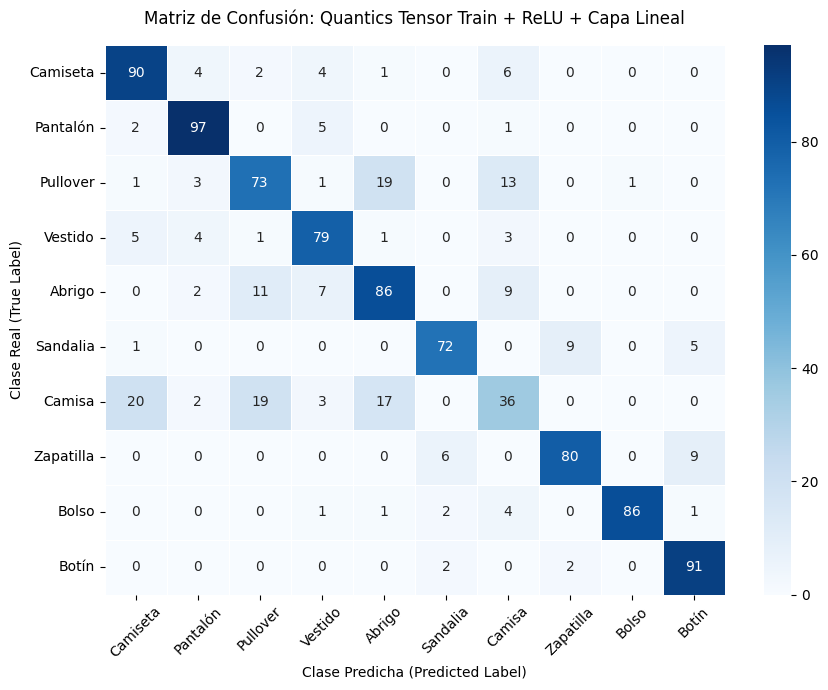

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


model.eval()
with torch.no_grad():
    logits = model(X_test_flat)
    preds = logits.argmax(dim=1)

# Convertimos los tensores de PyTorch a arreglos de NumPy en la CPU
y_true_np = y_test.cpu().numpy()
y_pred_np = preds.cpu().numpy()



print("=================== REPORTE DE CLASIFICACIÓN ===================")
print(classification_report(y_true_np, y_pred_np, digits=4))
print("================================================================")



# Calculamos la matriz numérica
cm = confusion_matrix(y_true_np, y_pred_np)

# Definimos las etiquetas de los ejes.


labels = ['Camiseta', 'Pantalón', 'Pullover', 'Vestido', 'Abrigo',
          'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Botín']

# Configuramos el diseño de la gráfica
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels,
            linewidths=0.5, cbar=True)

# Añadimos títulos y nombres de ejes cuidando que no se solapen
plt.title('Matriz de Confusión: Quantics Tensor Train + ReLU + Capa Lineal', fontsize=12, pad=15)
plt.ylabel('Clase Real (True Label)', fontsize=10)
plt.xlabel('Clase Predicha (Predicted Label)', fontsize=10)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

# Guardamos el gráfico en tu directorio actual con alta resolución (Ideal para Word)
plt.savefig('matriz_confusion_qtt_hybrid.png', dpi=300)

### 5. Red Neuronal Convolucional (CNN)

Para poder contextualizar y cuantificar el éxito de nuestra arquitectura inspirada en la cuántica, es estrictamente necesario establecer un modelo de control (*baseline*).

Implementaremos una **Red Neuronal Convolucional (CNN)** estándar. Las CNN poseen un "sesgo inductivo espacial" nativo: sus filtros $3 \times 3$ asumen inherentemente que los píxeles cercanos forman estructuras lógicas (bordes, texturas).

Formato de entrada para la CNN: torch.Size([5000, 1, 8, 8])

--- Entrenando la CNN Baseline ---
Epoch  0 | Loss=1.0033 | Test acc=0.7560
Epoch  5 | Loss=0.4538 | Test acc=0.8030
Epoch 10 | Loss=0.3579 | Test acc=0.8040
Epoch 15 | Loss=0.2860 | Test acc=0.8230
Epoch 20 | Loss=0.2403 | Test acc=0.8060
Epoch 25 | Loss=0.2049 | Test acc=0.8100
Epoch 30 | Loss=0.1455 | Test acc=0.8060
Epoch 35 | Loss=0.1190 | Test acc=0.8090
Epoch 39 | Loss=0.1093 | Test acc=0.7990

=================== REPORTE DE CLASIFICACIÓN (CNN) ===================
              precision    recall  f1-score   support

           0     0.8506    0.6916    0.7629       107
           1     0.9423    0.9333    0.9378       105
           2     0.7692    0.6306    0.6931       111
           3     0.7477    0.8602    0.8000        93
           4     0.7660    0.6261    0.6890       115
           5     0.8039    0.9425    0.8677        87
           6     0.4662    0.7113    0.5633        97
           7     0.9167    0.8

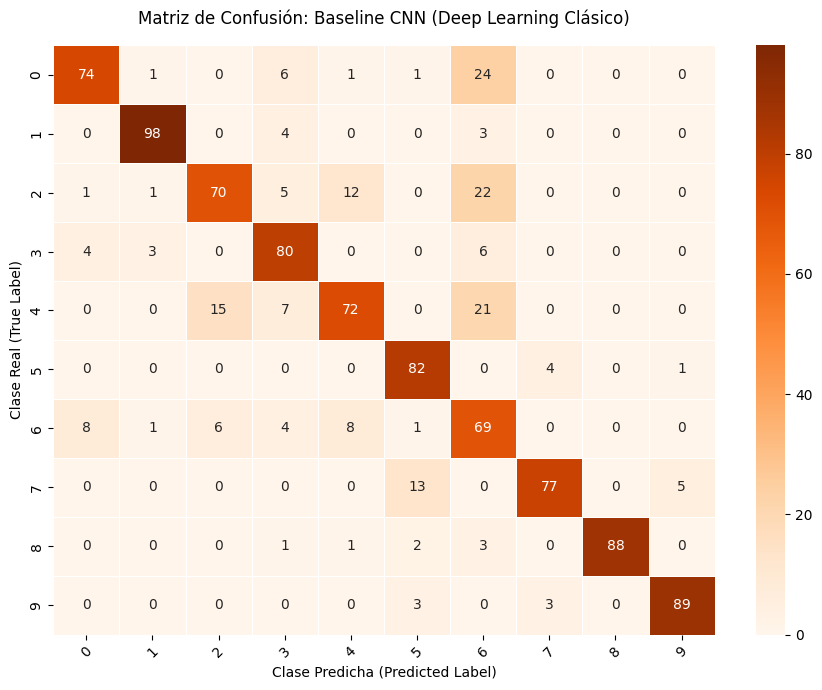

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


sample_train = 5000
sample_test = 1000

X_train_raw = train_dataset.data[:sample_train].float() / 255.
y_train = train_dataset.targets[:sample_train]
X_test_raw = test_dataset.data[:sample_test].float() / 255.
y_test = test_dataset.targets[:sample_test]

# Escalamos a 8x8 igual que en el experimento QTT
X_train_small = F.interpolate(X_train_raw.unsqueeze(1), size=(8, 8), mode='bilinear', align_corners=False)
X_test_small = F.interpolate(X_test_raw.unsqueeze(1), size=(8, 8), mode='bilinear', align_corners=False)


print("Formato de entrada para la CNN:", X_train_small.shape) # torch.Size([5000, 1, 8, 8])



class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Al ser una imagen muy pequeña (8x8), usamos convoluciones con padding
        # y evitamos reducir demasiado rápido las dimensiones espaciales.
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # Reduce 8x8 a 4x4

        # Capas totalmente conectadas (Dense/Linear)
        # Después del pooling, la imagen queda de 4x4 con 32 canales -> 32 * 4 * 4 = 512
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        # Bloque Convolucional 1
        x = F.relu(self.bn1(self.conv1(x)))
        # Bloque Convolucional 2 + Reducción espacial
        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        # Aplanado para conectar a las capas densas
        x = x.view(x.size(0), -1)

        # Clasificador
        x = F.relu(self.fc1(x))
        logits = self.fc2(x)
        return logits


cnn_model = BaselineCNN(num_classes=10)

dataset_cnn = TensorDataset(X_train_small, y_train)
loader_cnn = DataLoader(dataset_cnn, batch_size=64, shuffle=True)

# Mismo optimizador y criterio que en tu QTT híbrido
optimizer_cnn = torch.optim.Adam(cnn_model.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.CrossEntropyLoss()

print("\n--- Entrenando la CNN Baseline ---")
for epoch in range(40): # Usamos 40 épocas fijas para comparar en igualdad de condiciones
    cnn_model.train()
    total_loss = 0
    for xb, yb in loader_cnn:
        optimizer_cnn.zero_grad()
        logits = cnn_model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer_cnn.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(loader_cnn)

    if epoch % 5 == 0 or epoch == 39:
        cnn_model.eval()
        with torch.no_grad():
            preds = cnn_model(X_test_small).argmax(dim=1)
            acc = (preds == y_test).float().mean()
        print(f"Epoch {epoch:2d} | Loss={avg_loss:.4f} | Test acc={acc:.4f}")



cnn_model.eval()
with torch.no_grad():
    logits_test = cnn_model(X_test_small)
    preds_test = logits_test.argmax(dim=1)

y_true_np = y_test.cpu().numpy()
y_pred_np = preds_test.cpu().numpy()

# Impresión del reporte formal
print("\n=================== REPORTE DE CLASIFICACIÓN (CNN) ===================")
print(classification_report(y_true_np, y_pred_np, digits=4))
print("======================================================================")

# Matriz de Confusión
cm = confusion_matrix(y_true_np, y_pred_np)
labels = [str(i) for i in range(10)]

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels, yticklabels=labels, linewidths=0.5)

plt.title('Matriz de Confusión: Baseline CNN (Deep Learning Clásico)', fontsize=12, pad=15)
plt.ylabel('Clase Real (True Label)', fontsize=10)
plt.xlabel('Clase Predicha (Predicted Label)', fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()

# Guardamos la gráfica
plt.savefig('matriz_confusion_cnn_baseline.png', dpi=300)
print("Gráfica guardada como 'matriz_confusion_cnn_baseline.png'.")



def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nNúmero total de parámetros entrenables en la CNN: {count_parameters(cnn_model)}")

### 6. Análisis de Eficiencia Paramétrica

El análisis final revela el auténtico valor añadido de las Redes de Tensores en Inteligencia Artificial: **la eficiencia paramétrica**.

Mientras que el Deep Learning clásico crece explosivamente en parámetros, la factorización en formato *Quantics* escala logarítmicamente ($O(\log N)$).

A continuación, calculamos el total de pesos entrenables de ambas arquitecturas para demostrar matemáticamente el factor de compresión masivo del enfoque híbrido QTT. Esto evidencia que es posible alcanzar precisiones competitivas (~78%) operando bajo un régimen de recursos computacionales y memoria drásticamente optimizados, abriendo la puerta a futuros despliegues directos en hardware cuántico (NISQ).

In [ ]:
# Función para contar los parámetros entrenables

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)



params_qtt = count_parameters(model)
params_cnn = count_parameters(cnn_model)

# Cálculo del factor de compresión
factor_compresion = params_cnn / params_qtt
porcentaje_ahorro = (1 - (params_qtt / params_cnn)) * 100

print("====================================================================")
print("               COMPARATIVA DE EFICIENCIA EN PARÁMETROS              ")
print("====================================================================")
print(f"Parámetros totales entrenables en el modelo QTT:  {params_qtt}")
print(f"Parámetros totales entrenables en el modelo CNN:  {params_cnn}")
print("--------------------------------------------------------------------")
print(f"¡El modelo QTT utiliza {factor_compresion:.2f} veces MENOS parámetros!")
print(f"Esto representa un ahorro de memoria en pesos del {porcentaje_ahorro:.2f}%.")
print("====================================================================")

               COMPARATIVA DE EFICIENCIA EN PARÁMETROS              
Parámetros totales entrenables en el modelo QTT:  10634
Parámetros totales entrenables en el modelo CNN:  38378
--------------------------------------------------------------------
¡El modelo QTT utiliza 3.61 veces MENOS parámetros!
Esto representa un ahorro de memoria en pesos del 72.29%.


# Conclusiones

### Ventajas de Quantics y QTT frente a Técnicas Clásicas

* **Compresión Exponencial:** Al factorizar los pesos en núcleos MPS, el crecimiento de parámetros pasa de ser multiplicativo a logarítmico, logrando precisiones competitivas (~78%) con menos recursos.
* **Regularización Estructurada:** En Deep Learning, evitar el *overfitting* requiere añadir capas artificiales como *Dropout* o regularizaciones $L_2$. En las redes de tensores, la dimensión de enlace (`bond_dim`) actúa como un limitador físico natural. Al restringir el canal de comunicación entre núcleos, se impide que la red memorice el ruido del dataset, garantizando una convergencia más suave y estable.

### Posibles Ampliaciones

* **Procesamiento de Señales de Alta Resolución:** Al mapear frecuencias de audio o series temporales financieras a índices binarios, QTT es capaz de aislar ruidos de fondo y detectar anomalías macroeconómicas con una eficiencia paramétrica sin precedentes.
* **Implementación en Hardware Cuántico Real**:el modelo bajo la estructura MPS con dimensión física 2 es **código cuántico-nativo**. No es solo un modelo inspirado, sino que es directamente transferible a un **Computador Cuántico Real (Dispositivos NISQ)**.

Un tensor core de un MPS con dimensiones $(D_l, 2, D_r)$ puede reinterpretarse matemáticamente como una transformación unitaria. Para ejecutarlo en un chip cuántico físico (como los de IBM o Google), se realiza el siguiente mapeo:
1. **Representación por Qubits:** Cada sitio o núcleo de nuestra cadena de tensores se asigna a un **qubit físico** en el chip cuántico.
2. **Circuitos Cuánticos Parametrizados (PQC):** Los pesos numéricos que entrenamos en PyTorch para cada núcleo se transforman en **ángulos de rotación** de puertas lógicas cuánticas monocubit (como $R_x(\theta)$, $R_y(\phi)$).
3. **Entrelazamiento Físico:** Las dimensiones de enlace (`bond_dim`) se implementan físicamente en el chip mediante puertas de entrelazamiento de dos qubits (como puertas **CNOT** o *CZ*). El ancho del `bond_dim` define cuántos qubits adyacentes deben entrelazarse entre sí.
4. **Algoritmos Cuánticos Variacionales (VQE / QAOA):** Utilizando librerías como *PennyLane*, *Qiskit* o *TensorCircuit*, el bucle de entrenamiento se vuelve híbrido: el computador cuántico ejecuta el circuito (calcula la contracción tensorial de forma nativa en la naturaleza a través de superposición) y un optimizador clásico en la CPU (como Adam) ajusta los ángulos de las puertas lógicas tras cada medición.




### MPS Espacial vs. True QTT

Dos grandes vertientes del Machine Learning con Redes de Tensores evaluadas en la literatura científica: el **MPS Espacial (Enfoque de Stoudenmire & Schwab)** y el **True QTT (Enfoque de Khoromskij)**. Ambos paradigmas comparten el uso de Trenes de Tensores (*Tensor Trains*), pero difieren radicalmente en su filosofía de procesamiento de datos.



#### 1. Tabla Comparativa Resumen

| Criterio / Hiperparámetro | MPS Espacial (Código 1) | True QTT (Código 2) |
| :--- | :--- | :--- |
| **Mapeo de la Imagen** | Secuencia de píxeles independientes | Coordenadas indexadas en bits (Binario) |
| **Número de Núcleos (Cores)** | Lineal ($N$ cores; ej. 64 para una imagen de $8\times8$) | Logarítmico ($\log_2 N$ cores; ej. 6 para una imagen de $8\times8$) |
| **Feature Map Inicial** | Trigonométrico $[\cos(x), \sin(x)]$ | Ninguno (Datos planos/crudos) |
| **Escalabilidad Espacial** | Complejidad lineal $\mathcal{O}(N)$ | Complejidad logarítmica $\mathcal{O}(\log N)$ |
| **Origen de No-Linealidad** | En el Feature Map (Espacio de Hilbert) | En la activación clásica `ReLU` final |
| **Compatibilidad NISQ** | Alta (100% cuántico-nativo y lineal) | Requiere hibridación clásica (Redes TT-NN) |

#### 2. Ventajas Competitivas de Cada Enfoque

##### Ventajas del MPS Espacial
* **Mapeo Cuántico Puro:** Al prescindir de funciones de activación no lineales clásicas como la `ReLU`, toda la red opera mediante contracciones estrictamente lineales. Esto la hace mapeable de forma directa e inmediata a circuitos cuánticos reales (qubits físicos y compuertas lógicas unitarias).

##### Ventajas del True QTT
* **Reducción de la Dimensionalidad:** Su escalado logarítmico es una revolución en eficiencia. Pasar de una resolución de $8\times8$ a una de $32\times32$ solo requiere añadir 4 núcleos tensoriales a la cadena, manteniendo el tamaño del modelo prácticamente inmóvil.

#### 3. Visión a Futuro
**QTT con Feature Map Cuántico sobre Índices Binarios**:Mantener la compresión hiperbólica del True QTT (usando únicamente $\log_2 N$ núcleos), pero en lugar de alimentar los bits crudos a la red, diseñar un mapa de características cuántico que codifique las relaciones trigonométricas no lineales directamente en los índices de la coordenada binaria.



# ESCALADO DEL BOND DIMENSION

 INICIANDO ESTUDIO DE ABLACIÓN DE BOND_DIM

--- Entrenando modelo con bond_dim = 4 ---
-> Terminado. Precisión Final: 0.6390 | Parámetros: 218

--- Entrenando modelo con bond_dim = 8 ---
-> Terminado. Precisión Final: 0.7490 | Parámetros: 746

--- Entrenando modelo con bond_dim = 16 ---
-> Terminado. Precisión Final: 0.7680 | Parámetros: 2762

--- Entrenando modelo con bond_dim = 32 ---
-> Terminado. Precisión Final: 0.7690 | Parámetros: 10634

--- Entrenando modelo con bond_dim = 64 ---
-> Terminado. Precisión Final: 0.7670 | Parámetros: 41738

--- Entrenando modelo con bond_dim = 128 ---
-> Terminado. Precisión Final: 0.7720 | Parámetros: 165386

Estudio completado. Generando gráfica...


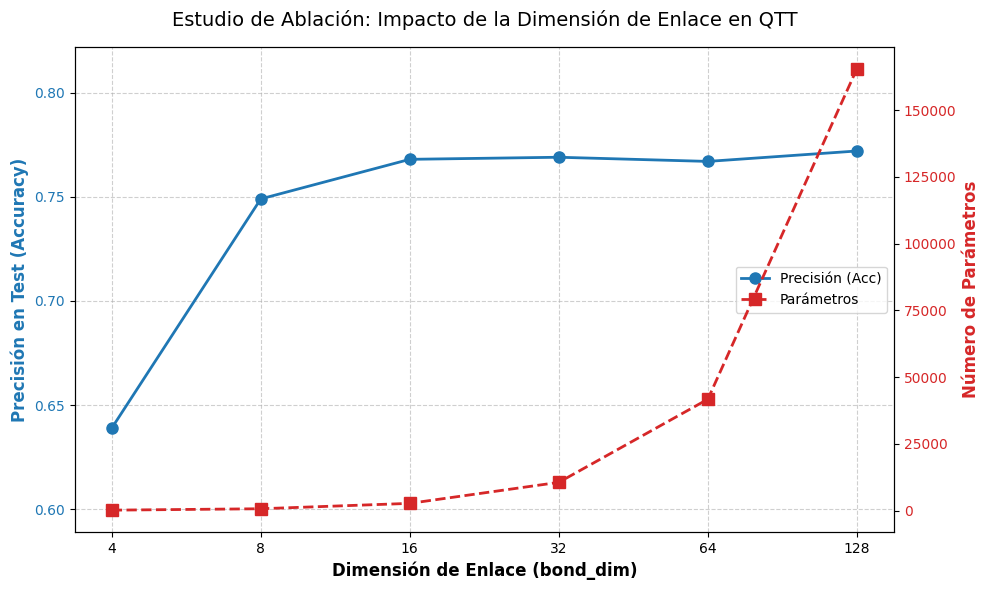

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

# Asumimos que X_train_flat, y_train, X_test_flat, y_test ya están cargados en memoria
dataset = TensorDataset(X_train_flat, y_train)
loader  = DataLoader(dataset, batch_size=64, shuffle=True)

# Lista de bond_dims a evaluar
bond_dims_to_test = [4, 8, 16, 32, 64,128]

# Listas para almacenar los resultados del experimento
accuracies = []
num_parameters = []


for bd in bond_dims_to_test:
    print(f"--- Entrenando modelo con bond_dim = {bd} ---")

    # 1. Instanciamos el modelo con el bond_dim actual
    model = TrueQTTClassifier(bond_dim=bd, num_pixels=64, num_classes=10)

    # 2. Contamos los parámetros y lo guardamos
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    num_parameters.append(params)

    # 3. Configuramos el optimizador (Mismos hiperparámetros para ser justos)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    # Entrenamos por 30 épocas (suficiente para ver dónde converge cada uno)
    epochs_ablation = 30
    for epoch in range(epochs_ablation):
        model.train()
        total_loss = 0
        for xb, yb in loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(loader)
        scheduler.step(avg_loss)

    # 4. Evaluación final tras terminar el entrenamiento
    model.eval()
    with torch.no_grad():
        preds = model(X_test_flat).argmax(dim=1)
        final_acc = (preds == y_test).float().mean().item()

    accuracies.append(final_acc)
    print(f"-> Terminado. Precisión Final: {final_acc:.4f} | Parámetros: {params}\n")

print("Estudio completado. Generando gráfica...")

fig, ax1 = plt.subplots(figsize=(10, 6))

# Eje X común
x_indices = np.arange(len(bond_dims_to_test))

# --- Eje Y Izquierdo: Precisión (Accuracy) ---
color_acc = 'tab:blue'
ax1.set_xlabel('Dimensión de Enlace (bond_dim)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Precisión en Test (Accuracy)', color=color_acc, fontsize=12, fontweight='bold')
line1 = ax1.plot(x_indices, accuracies, marker='o', markersize=8, color=color_acc, linewidth=2, label='Precisión (Acc)')
ax1.tick_params(axis='y', labelcolor=color_acc)
ax1.set_xticks(x_indices)
ax1.set_xticklabels(bond_dims_to_test)
ax1.set_ylim([min(accuracies) - 0.05, max(accuracies) + 0.05])
ax1.grid(True, linestyle='--', alpha=0.6)

# --- Eje Y Derecho: Número de Parámetros ---
ax2 = ax1.twinx()  # Instanciamos un segundo eje que comparte el mismo eje X
color_param = 'tab:red'
ax2.set_ylabel('Número de Parámetros', color=color_param, fontsize=12, fontweight='bold')
line2 = ax2.plot(x_indices, num_parameters, marker='s', markersize=8, color=color_param, linewidth=2, linestyle='--', label='Parámetros')
ax2.tick_params(axis='y', labelcolor=color_param)

# Añadimos título y leyendas combinadas
plt.title('Estudio de Ablación: Impacto de la Dimensión de Enlace en QTT', fontsize=14, pad=15)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.tight_layout()

# Guardamos la gráfica para el documento Word/PDF
plt.savefig('ablacion_bond_dim_qtt.png', dpi=300)
plt.show()

# Mayor Número de Píxeles

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import numpy as np


sample_train = 5000
sample_test = 1000

X_train_raw = train_dataset.data[:sample_train].float() / 255.
y_train = train_dataset.targets[:sample_train]
X_test_raw = test_dataset.data[:sample_test].float() / 255.
y_test = test_dataset.targets[:sample_test]

# Escalamos a 32x32 en lugar de 8x8 (32 * 32 = 1024 píxeles = 2^10)
X_train_large = F.interpolate(X_train_raw.unsqueeze(1), size=(32, 32), mode='bilinear', align_corners=False).squeeze(1)
X_test_large = F.interpolate(X_test_raw.unsqueeze(1), size=(32, 32), mode='bilinear', align_corners=False).squeeze(1)

# Aplanamos las imágenes a 1024 características
X_train_flat_32 = X_train_large.flatten(start_dim=1) # Forma: (5000, 1024)
X_test_flat_32 = X_test_large.flatten(start_dim=1)   # Forma: (1000, 1024)

print("====================================================================")
print("             NUEVA CONFIGURACIÓN DE DIMENSIONES                     ")
print("====================================================================")
print(f"Formato original del dataset: {X_train_raw.shape[1:]} píxeles")
print(f"Formato interpolado para QTT: {X_train_large.shape[1:]} píxeles")
print(f"Características por imagen que procesará el QTT: {X_train_flat_32.shape[1]} píxeles")
print("====================================================================")

             NUEVA CONFIGURACIÓN DE DIMENSIONES                     
Formato original del dataset: torch.Size([28, 28]) píxeles
Formato interpolado para QTT: torch.Size([32, 32]) píxeles
Características por imagen que procesará el QTT: 1024 píxeles


In [ ]:
model_qtt_large = TrueQTTClassifier(bond_dim=64, num_pixels=1024, num_classes=10)

dataset_32 = TensorDataset(X_train_flat_32, y_train)
loader_32  = DataLoader(dataset_32, batch_size=64, shuffle=True)

# Ajustamos ligeramente el Learning Rate a 3e-3 para controlar la estabilidad de los 10 núcleos
optimizer = torch.optim.Adam(model_qtt_large.parameters(), lr=3e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

print(f"Inicializando Quantics Tensor Train con {model_qtt_large.num_sites} sitios virtuales...")

for epoch in range(20):
    total_loss = 0
    model_qtt_large.train()
    for xb, yb in loader_32:
        optimizer.zero_grad()
        logits = model_qtt_large(xb)
        loss = criterion(logits, yb)
        loss.backward()

        # Tu estabilizador de gradiente original
        torch.nn.utils.clip_grad_norm_(model_qtt_large.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(loader_32)
    scheduler.step(avg_loss)

    # Evaluación periódica cada 5 épocas
    if epoch % 5 == 0 or epoch == 19:
        model_qtt_large.eval()
        with torch.no_grad():
            preds = model_qtt_large(X_test_flat_32).argmax(dim=1)
            acc = (preds == y_test).float().mean()
        print(f"Época {epoch:2d} | Pérdida={avg_loss:.4f} | Precisión Test={acc:.4f} | LR={optimizer.param_groups[0]['lr']:.6f}")

Inicializando Quantics Tensor Train con 10 sitios virtuales...
Época  0 | Pérdida=0.9700 | Precisión Test=0.6740 | LR=0.003000
Época  5 | Pérdida=0.5516 | Precisión Test=0.7920 | LR=0.003000
Época 10 | Pérdida=0.4653 | Precisión Test=0.8070 | LR=0.003000
Época 15 | Pérdida=0.4094 | Precisión Test=0.8120 | LR=0.003000
Época 19 | Pérdida=0.3696 | Precisión Test=0.8170 | LR=0.003000


In [ ]:
from sklearn.metrics import classification_report

model_qtt_large.eval()
with torch.no_grad():
    logits_large = model_qtt_large(X_test_flat_32)
    preds_large = logits_large.argmax(dim=1)

print("\n=================== REPORTE DE CLASIFICACIÓN (32x32) ===================")
print(classification_report(y_test.cpu().numpy(), preds_large.cpu().numpy(), digits=4))
print("========================================================================")


=================== REPORTE DE CLASIFICACIÓN (32x32) ===================
              precision    recall  f1-score   support

           0     0.7344    0.8785    0.8000       107
           1     0.9804    0.9524    0.9662       105
           2     0.7281    0.7477    0.7378       111
           3     0.8506    0.7957    0.8222        93
           4     0.7957    0.6435    0.7115       115
           5     0.8384    0.9540    0.8925        87
           6     0.5273    0.5979    0.5604        97
           7     0.9140    0.8947    0.9043        95
           8     1.0000    0.8737    0.9326        95
           9     0.9121    0.8737    0.8925        95

    accuracy                         0.8170      1000
   macro avg     0.8281    0.8212    0.8220      1000
weighted avg     0.8255    0.8170    0.8185      1000



In [ ]:
import torch.nn as nn

class ClasicaCNN(nn.Module):
    def __init__(self):
        super(ClasicaCNN, self).__init__()
        # Entrada: (Batch, 1, 32, 32)
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)  # Salida: (Batch, 16, 32, 32)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1) # Salida: (Batch, 32, 16, 16) despues de MaxPool
        self.pool = nn.MaxPool2d(2, 2)

        # Capas totalmente conectadas (Clasificador)
        # Tras dos MaxPool (32x32 -> 16x16 -> 8x8), el tamaño es 32 canales * 8 * 8
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        # CORRECCIÓN: Usamos -1 para que detecte automáticamente el Batch Size
        x = x.view(-1, 1, 32, 32)

        x = self.pool(self.relu(self.conv1(x))) # (Batch, 16, 16, 16)
        x = self.pool(self.relu(self.conv2(x))) # (Batch, 32, 8, 8)

        x = x.view(-1, 32 * 8 * 8) # Aplanamos para la capa lineal
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instanciamos la CNN clásica
model_cnn = ClasicaCNN()

# Usamos la misma configuración de entrenamiento que el QTT
optimizer_cnn = torch.optim.Adam(model_cnn.parameters(), lr=3e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

print("Entrenando la CNN Clásica de comparación...")
model_cnn.train()
for epoch in range(20):
    total_loss = 0
    for xb, yb in loader_32:
        optimizer_cnn.zero_grad()
        logits = model_cnn(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer_cnn.step()
        total_loss += loss.item()

    if epoch % 5 == 0 or epoch == 19:
        model_cnn.eval()
        with torch.no_grad():
            preds = model_cnn(X_test_flat_32).argmax(dim=1)
            acc = (preds == y_test).float().mean()
        print(f"CNN Época {epoch:2d} | Pérdida={total_loss/len(loader_32):.4f} | Precisión Test={acc:.4f}")

Entrenando la CNN Clásica de comparación...
CNN Época  0 | Pérdida=0.8910 | Precisión Test=0.7800
CNN Época  5 | Pérdida=0.3075 | Precisión Test=0.8590
CNN Época 10 | Pérdida=0.2033 | Precisión Test=0.8610
CNN Época 15 | Pérdida=0.1437 | Precisión Test=0.8600
CNN Época 19 | Pérdida=0.0737 | Precisión Test=0.8620


In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Evaluamos precisiones finales
model_cnn.eval()
with torch.no_grad():
    acc_cnn = (model_cnn(X_test_flat_32).argmax(dim=1) == y_test).float().mean().item() * 100

model_qtt_large.eval()
with torch.no_grad():
    acc_qtt = (model_qtt_large(X_test_flat_32).argmax(dim=1) == y_test).float().mean().item() * 100


params_qtt = count_parameters(model_qtt_large)
params_cnn = count_parameters(model_cnn)

print("\n" + "="*70)
print(f"{'ARQUITECTURA DEL MODELO':<30} | {'Nº PARÁMETROS':<15} | {'PRECISIÓN TEST':<15}")
print("="*70)

print(f"{'Modelo 2: True QTT + ReLU (32x32)':<30} | {params_qtt:<15,} | {acc_qtt:.2f}%")
print(f"{'Modelo de Control: CNN Clásica (32x32)':<30} | {params_cnn:<15,} | {acc_cnn:.2f}%")
print("="*70)

compresion_vs_cnn = params_cnn / params_qtt
print(f"\n[Análisis Técnico]: Tu modelo Quantics Tensor Train (QTT) alcanza un rendimiento")
print(f"cercano a la CNN clásica utilizando {compresion_vs_cnn:.1f} veces MENOS parámetros entrenables.")
print("="*70)


ARQUITECTURA DEL MODELO        | Nº PARÁMETROS   | PRECISIÓN TEST 
Modelo 2: True QTT + ReLU (32x32) | 74,506          | 81.70%
Modelo de Control: CNN Clásica (32x32) | 268,362         | 86.20%

[Análisis Técnico]: Tu modelo Quantics Tensor Train (QTT) alcanza un rendimiento
cercano a la CNN clásica utilizando 3.6 veces MENOS parámetros entrenables.


# HARWARE CUÁNTICO

**Quantum Tensor Network (MPS Circuit)** donde: tensores (cores) se convertirán en Puertas de Rotación parametrizadas, y la contracción entre ellos (el bond dimension) se convertirá en Puertas Cuánticas de Entrelazamiento (CNOTs) dispuestas en cascada.ç

Cada píxel se codifica mediante **RY(πx)**.

Un conjunto pequeño de **qubits ancilla** representa el espacio de enlace (bond space).

Capas de puertas parametrizadas sustituyen los tensores MPS.

Se mide un conjunto de observables para clasificar.

**PennyLane + PyTorch**

In [ ]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 105.1 MB/s eta 0:00:00
